# Предсказание значений индекса качества воздуха (ИКВ) с помощью машинного обучения (классификация)
Используемые модели:
1. RandomForestClassifier
2. LogisticRegression
3. KNeighborsClassifier
4. XGBoost
5. LightGBM
6. CatBoost

In [1]:
# Станции городского типа
# Основные
intervals_NO2_hourly = [
    (0, 50.999, 0, 25),
    (51, 100.999, 26, 50),
    (101, 200.999, 51, 75),
    (201, 400.999, 76, 100),
    (401, float('inf'), 100, float('inf'))
]

intervals_PM10_hourly = [
    (0, 25.999, 0, 25),
    (26, 50.999, 26, 50),
    (51, 90.999, 51, 75),
    (91, 180.999, 76, 100),
    (181, float('inf'), 100, float('inf'))
]

intervals_PM10_daily = [
    (0, 15.999, 0, 25),
    (16, 30.999, 26, 50),
    (31, 50.999, 51, 75),
    (51, 100.999, 76, 100),
    (101, float('inf'), 100, float('inf'))
]

intervals_O3_hourly = [
    (0, 60.999, 0, 25),
    (61, 120.999, 26, 50),
    (121, 180.999, 51, 75),
    (181, 240.999, 76, 100),
    (241, float('inf'), 100, float('inf'))
]

# Дополнительные
intervals_PM25_hourly = [
    (0, 15.999, 0, 25),
    (16, 30.999, 26, 50),
    (31, 55.999, 51, 75),
    (56, 110.999, 76, 100),
    (111, float('inf'), 100, float('inf'))
]

intervals_PM25_daily = [
    (0, 10.999, 0, 25),
    (11, 20.999, 26, 50),
    (21, 30.999, 51, 75),
    (31, 60.999, 76, 100),
    (61, float('inf'), 100, float('inf'))
]

intervals_CO_8h = [
    (0, 5000.999, 0, 25),
    (5001, 7500.999, 26, 50),
    (7501, 10000.999, 51, 75),
    (10001, 20000.999, 76, 100),
    (20001, float('inf'), 100, float('inf'))
]

intervals_SO2_hourly = [
    (0, 50.999, 0, 25),
    (51, 100.999, 26, 50),
    (101, 350.999, 51, 75),
    (351, 500.999, 76, 100),
    (501, float('inf'), 100, float('inf'))
]

def calc_ikv(conc, intervals):
    for c_min, c_max, ikv_min, ikv_max in intervals:
        if c_min <= conc <= c_max:
            return round(ikv_min + (conc - c_min) * (ikv_max - ikv_min) / (c_max - c_min), 2)
    return None

# Станции городского типа
# Основные
def calc_ikv_NO2_hourly(conc):
    return calc_ikv(conc, intervals_NO2_hourly)

def calc_ikv_PM10_hourly(conc):
    return calc_ikv(conc, intervals_PM10_hourly)

def calc_ikv_PM10_daily(conc):
    return calc_ikv(conc, intervals_PM10_daily)

def calc_ikv_O3_hourly(conc):
    return calc_ikv(conc, intervals_O3_hourly)

# Дополнительные
def calc_ikv_PM2_5_hourly(conc):
    return calc_ikv(conc, intervals_PM25_hourly)

def calc_ikv_PM2_5_daily(conc):
    return calc_ikv(conc, intervals_PM25_daily)

def calc_ikv_CO_8_hourly(conc):
    return calc_ikv(conc, intervals_CO_8h)

def calc_ikv_SO2_hourly(conc):
    return calc_ikv(conc, intervals_SO2_hourly)

### Загрузка и объединение данных

In [2]:
import pandas as pd

filenames = [
    "st_01", "st_02", "st_05", "st_07", "st_09",
    "st_26", "st_27", "tr_03", "tr_04", "tr_05", "tr_06"
]

all_dfs = []

for name in filenames:
    try:
        file_path = name + ".csv"
        df_station = pd.read_csv(file_path, encoding="cp1251", sep=";")
        all_dfs.append(df_station)
    except FileNotFoundError:
        print(f"Файл {file_path} не найден, пропускаем.")
        continue

full_df = pd.concat(all_dfs, ignore_index=True)

### Базовая обработка данных и расчёт ИКВ

In [4]:
import pandas as pd
import numpy as np

# Список файлов
filenames = [
    "st_01", "st_02", "st_05", "st_07", "st_09",
    "st_26", "st_27", "tr_03", "tr_04", "tr_05", "tr_06"
]

# Список для сбора почасовых DataFrame'ов по всем станциям
all_hourly_dfs = []

# Классификация ИКВ для ЕС
def classify_ikv_es(value):
    if pd.isna(value):
        return np.nan
    elif value < 20:
        return 0 # "Очень низкий"
    elif value < 40:
        return 1 # "Низкий"
    elif value < 60:
        return 2 # "Средний"
    elif value < 80:
        return 3 # "Высокий"
    else:
        return 4 # "Очень высокий"

for name in filenames:
    file = name + ".csv"
    print(f"\n--- Обработка файла: {file} ---")

    df = pd.read_csv(file, encoding="cp1251", sep=";")

    df["Время"] = pd.to_datetime(df["Время"], dayfirst=True, errors='coerce')
    df = df.dropna(subset=["Время"]) # Удаляем строки, где время не удалось распарсить
    df = df.set_index("Время") # Устанавливаем 'Время' как индекс

    # Ресэмплируем данные для разных агрегаций
    # Здесь важно, что resample создает новый индекс, поэтому мы его сохраняем
    df_hourly = df.resample("1H").mean().round(3)
    df_8_hourly = df.resample("8H").mean().round(3)
    df_daily = df.resample("1D").mean().round(3)

    # --- Расчёт ИКВ для каждой частоты ---

    # Почасовые ИКВ
    if "Диоксид азота" in df_hourly.columns:
        df_hourly["ИКВ Диоксид азота"] = (df_hourly["Диоксид азота"] * 1000).apply(calc_ikv_NO2_hourly)
    if "Озон" in df_hourly.columns:
        df_hourly["ИКВ Озон почасовой"] = (df_hourly["Озон"] * 1000).apply(calc_ikv_O3_hourly)
    if "Частицы 10 мкм" in df_hourly.columns:
        df_hourly["ИКВ Частицы 10 мкм"] = df_hourly["Частицы 10 мкм"].apply(calc_ikv_PM10_hourly)
    if "Частицы 2.5 мкм" in df_hourly.columns:
        df_hourly["ИКВ Частицы 2.5 мкм"] = df_hourly["Частицы 2.5 мкм"].apply(calc_ikv_PM2_5_hourly)
    if "Диоксид серы" in df_hourly.columns:
        df_hourly["ИКВ Диоксид серы"] = (df_hourly["Диоксид серы"] * 1000).apply(calc_ikv_SO2_hourly)

    # 8-часовые ИКВ
    if "Оксид углерода" in df_8_hourly.columns:
        df_8_hourly["ИКВ Оксид углерода"] = df_8_hourly["Оксид углерода"].apply(calc_ikv_CO_8_hourly)
        # Переиндексируем 8-часовые ИКВ к почасовому разрешению с ffill
        df_hourly["ИКВ Оксид углерода"] = df_8_hourly["ИКВ Оксид углерода"].reindex(df_hourly.index, method='ffill')

    # Суточные ИКВ
    if "Частицы 10 мкм" in df_daily.columns:
        df_daily["ИКВ Частицы 10 мкм (суточный)"] = df_daily["Частицы 10 мкм"].apply(calc_ikv_PM10_daily)
        # Переиндексируем суточные ИКВ к почасовому разрешению с ffill
        df_hourly["ИКВ Частицы 10 мкм (суточный)"] = df_daily["ИКВ Частицы 10 мкм (суточный)"].reindex(df_hourly.index, method='ffill')

    if "Частицы 2.5 мкм" in df_daily.columns:
        df_daily["ИКВ Частицы 2.5 мкм (суточный)"] = df_daily["Частицы 2.5 мкм"].apply(calc_ikv_PM2_5_daily)
        # Переиндексируем суточные ИКВ к почасовому разрешению с ffill
        df_hourly["ИКВ Частицы 2.5 мкм (суточный)"] = df_daily["ИКВ Частицы 2.5 мкм (суточный)"].reindex(df_hourly.index, method='ffill')

    # Определяем общий ИКВ для текущей станции
    # ИКВ столбцы, которые могут быть в df_hourly
    potential_ikv_columns = [
        "ИКВ Диоксид азота",
        "ИКВ Озон почасовой",
        "ИКВ Частицы 10 мкм",
        "ИКВ Частицы 2.5 мкм",
        "ИКВ Диоксид серы",
        "ИКВ Оксид углерода (8-часовой)", # Теперь добавлен после reindex
        "ИКВ Частицы 10 мкм (суточный)", # Теперь добавлен после reindex
        "ИКВ Частицы 2.5 мкм (суточный)"  # Теперь добавлен после reindex
    ]
    
    # Фильтруем только те ИКВ столбцы, которые фактически существуют в df_hourly
    actual_ikv_columns = [col for col in potential_ikv_columns if col in df_hourly.columns]

    if actual_ikv_columns:
        # max(axis=1, skipna=True) по умолчанию игнорирует NaN при поиске максимума
        df_hourly["ИКВ общий"] = df_hourly[actual_ikv_columns].max(axis=1)
    else:
        print(f"Предупреждение: Для станции {name} не найдено ни одного столбца ИКВ.")
        df_hourly["ИКВ общий"] = np.nan

    # Добавляем столбец с номером станции
    df_hourly['Номер станции'] = name
    
    # Добавляем рассчитанный DataFrame в список
    all_hourly_dfs.append(df_hourly.reset_index()) # reset_index() чтобы 'Время' стало столбцом для concat

# Объединяем все почасовые DataFrame'ы в один
if all_hourly_dfs:
    full_hourly_df = pd.concat(all_hourly_dfs, ignore_index=True)
    # Сортируем по времени и номеру станции для лучшей читаемости
    full_hourly_df.sort_values(by=['Время', 'Номер станции'], inplace=True)
    
    print("\n--- Итоговый объединённый почасовой DataFrame ---")
    print(full_hourly_df.info())
    print(full_hourly_df.head())
    print("\n--- Проверка наличия NaN в ИКВ столбцах в итоговом DataFrame ---")
    ikv_cols_in_full_df = [col for col in full_hourly_df.columns if col.startswith("ИКВ")]
    print(full_hourly_df[ikv_cols_in_full_df].isnull().sum())
    
    # Можно добавить классификацию ИКВ-ЕС для общего ИКВ, если нужно
    full_hourly_df["ИКВ-ЕС"] = full_hourly_df["ИКВ общий"].apply(classify_ikv_es)
    full_hourly_df['ИКВ-ЕС'] = full_hourly_df['ИКВ-ЕС'].astype('Int64')
    print("\n--- Начало итогового DataFrame с классификацией ИКВ-ЕС ---")
    print(full_hourly_df[['Время', 'Номер станции', 'ИКВ общий', 'ИКВ-ЕС']].head(10))

else:
    print("Не удалось обработать ни один файл. Итоговый DataFrame пуст.")


--- Обработка файла: st_01.csv ---

--- Обработка файла: st_02.csv ---

--- Обработка файла: st_05.csv ---

--- Обработка файла: st_07.csv ---

--- Обработка файла: st_09.csv ---

--- Обработка файла: st_26.csv ---

--- Обработка файла: st_27.csv ---

--- Обработка файла: tr_03.csv ---

--- Обработка файла: tr_04.csv ---

--- Обработка файла: tr_05.csv ---

--- Обработка файла: tr_06.csv ---

--- Итоговый объединённый почасовой DataFrame ---
<class 'pandas.core.frame.DataFrame'>
Int64Index: 296277 entries, 60493 to 296276
Data columns (total 43 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   Время                           296277 non-null  datetime64[ns]
 1   Номер                           250288 non-null  float64       
 2   Взвешенные в-ва                 56596 non-null   float64       
 3   Диоксид серы                    222362 non-null  float64       
 4   Оксид углерода     

### Подготовка данных для машинного обучения
###### Создание лаговых признаков, удаление неинформативных столбцов

In [6]:
import pandas as pd
import numpy as np

TARGET = "ИКВ-ЕС"

df_model = full_hourly_df.copy()

if "Время" in df_model.columns:
    # Преобразуем столбец "Время" в datetime, если он ещё не такой
    if not pd.api.types.is_datetime64_any_dtype(df_model["Время"]):
        df_model["Время"] = pd.to_datetime(df_model["Время"], errors='coerce')
    # Устанавливаем "Время" как индекс
    df_model.set_index("Время", inplace=True)
    df_model.sort_index(inplace=True) # Сортируем по индексу для корректной работы с временными рядами
else:
    # Если столбец "Время" отсутствует, но индекс уже datetime, это нормально.
    # Если индекс не datetime, но столбца "Время" нет - это проблема.
    if not pd.api.types.is_datetime64_any_dtype(df_model.index):
        raise TypeError("Индекс DataFrame не является DatetimeIndex и столбец 'Время' отсутствует.")


# 1. Временные признаки
df_model["час"] = df_model.index.hour
df_model["день_недели"] = df_model.index.dayofweek
df_model["месяц"] = df_model.index.month

# 2. Лаговые признаки для ИКВ
lags = [1, 2, 3, 6, 24]
for lag in lags:
    if TARGET in df_model.columns:
        # Важно: группировка по станции для лаговых признаков, чтобы не смешивать данные между станциями
        df_model[f'{TARGET}_lag_{lag}h'] = df_model.groupby("Номер станции")[TARGET].shift(lag)
    else:
        print(f"Предупреждение: Целевой столбец '{TARGET}' не найден. Лаговые признаки не будут созданы.")

# 3. Удаляем столбцы с большим количеством пропусков
min_valid_values = len(df_model) * 0.5
df_model = df_model.dropna(axis='columns', thresh=min_valid_values)
print(f"\nСтолбцы, оставленные после удаления пропусков: {df_model.columns.tolist()}")

# 4. Убираем неинформативные столбцы
# Целевая переменная расчитывается полностью на основе столбца "ИКВ общий",
# 'Номер станции совпадает' с "Номер", только хранит строковые значения - названия станций
columns_to_drop = ["ИКВ общий", "Номер станции"]

# Фильтруем список столбцов для удаления, оставляя только те, что реально существуют в DataFrame
existing_columns_to_drop = [col for col in columns_to_drop if col in df_model.columns]
df_model = df_model.drop(columns=existing_columns_to_drop, errors='ignore') # errors='ignore' чтобы не падать, если столбца нет

# 5. Заполняем оставшиеся пропуски медианой
numeric_cols = df_model.select_dtypes(include=np.number).columns
for col in numeric_cols:
    if df_model[col].isnull().any():
        median_val = df_model[col].median()
        df_model[col].fillna(median_val, inplace=True)

# 6. Удаляем строки, где лаговые признаки остались пустыми (первые несколько строк)
# Эти пропуски появляются в начале каждой группы (станции) из-за операции shift
#df_model.dropna(inplace=True)

if TARGET not in df_model.columns:
    raise ValueError(f"Целевая переменная '{TARGET}' отсутствует в данных после очистки!")


Столбцы, оставленные после удаления пропусков: ['Номер', 'Диоксид серы', 'Оксид углерода', 'Диоксид азота', 'Оксид азота', 'Сероводород', 'Аммиак', 'Температура', 'Влажность отн.', 'Направление ветра', 'Скорость ветра', 'ИКВ Диоксид азота', 'ИКВ Диоксид серы', 'ИКВ Оксид углерода', 'ИКВ общий', 'Номер станции', 'ИКВ-ЕС', 'час', 'день_недели', 'месяц', 'ИКВ-ЕС_lag_1h', 'ИКВ-ЕС_lag_2h', 'ИКВ-ЕС_lag_3h', 'ИКВ-ЕС_lag_6h', 'ИКВ-ЕС_lag_24h']


## Машинное обучение

### 1. RandomForestClassifier


--- Обучение модели RandomForestRegressor ---

--- Качество модели на тестовых данных ---
Точность (Accuracy): 0.9920

Матрица ошибок (Confusion Matrix):
[[45891    84     4     0     3]
 [  114 10326    46     0     0]
 [    8   117  2237    25     0]
 [    1     3    46   283     7]
 [    6     3     3     5    44]]

Отчёт по классификации (Classification Report):
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     45982
         1.0       0.98      0.98      0.98     10486
         2.0       0.96      0.94      0.95      2387
         3.0       0.90      0.83      0.87       340
         4.0       0.81      0.72      0.77        61

    accuracy                           0.99     59256
   macro avg       0.93      0.89      0.91     59256
weighted avg       0.99      0.99      0.99     59256



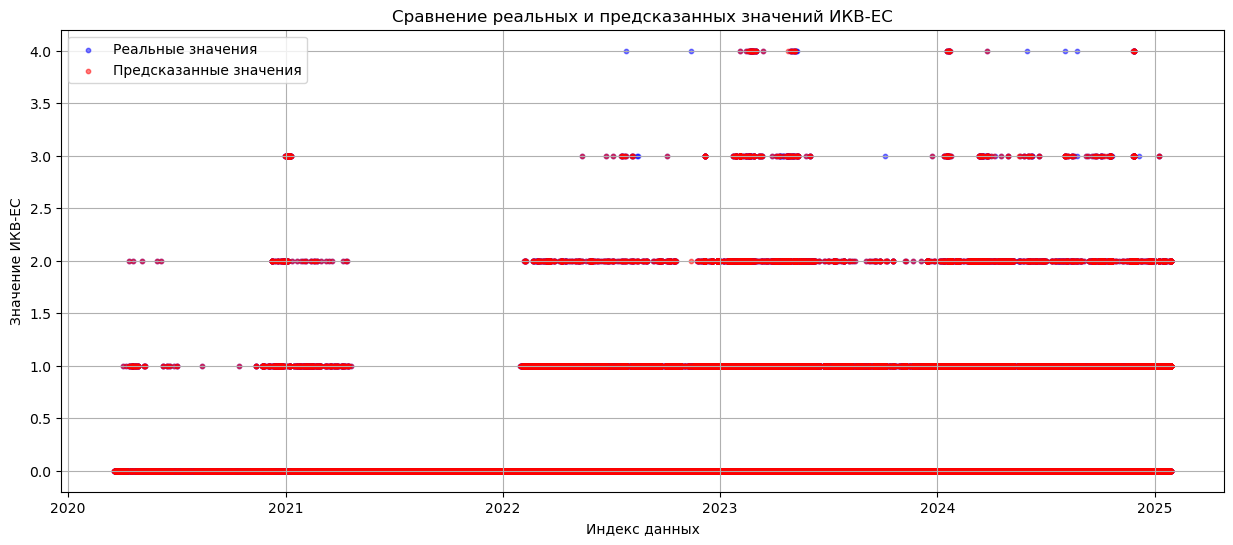

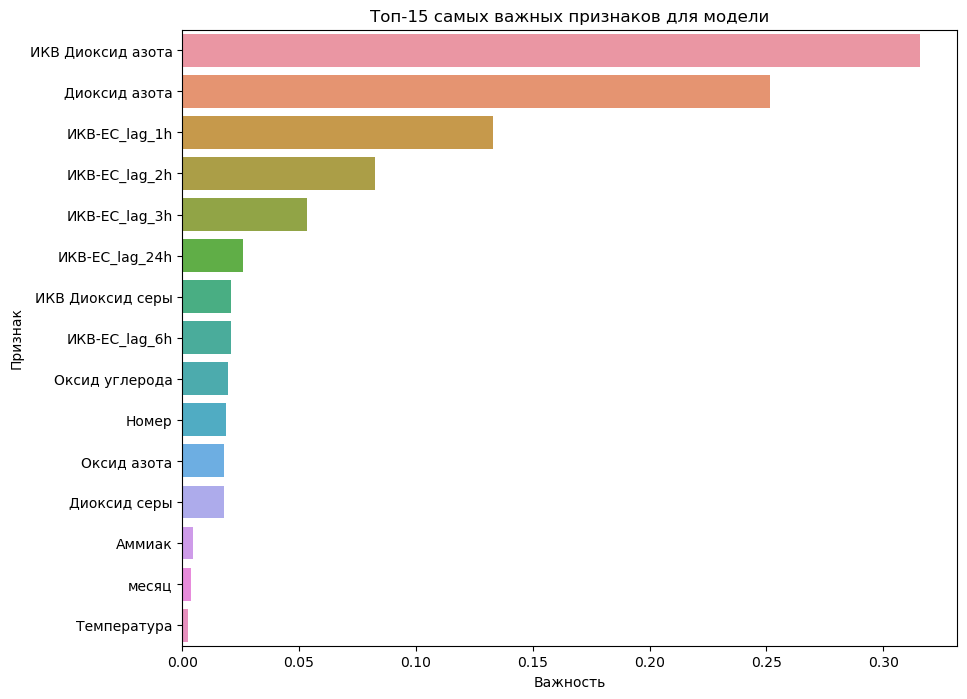

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Отделяем признаки (X) от целевой переменной (y)
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

# Разделяем данные на обучающую и тестовую выборки (80% на обучение, 20% на тест)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Инициализация RandomForestClassifier ---
rf_classifier = RandomForestClassifier(
    n_estimators=100,       # Количество деревьев в лесу
    max_features='sqrt',    # Количество признаков для рассмотрения при каждом разделении
    min_samples_leaf=5,     # Изменено: min_samples_split заменен на min_samples_leaf,
                            # что более характерно для классификатора и контролирует
                            # минимальное количество выборок в конечном листе.
    random_state=42,        # Для воспроизводимости
    n_jobs=-1               # Использовать все доступные ядра процессора для ускорения
)

print(f"\n--- Обучение модели RandomForestRegressor ---")
rf_classifier.fit(X_train, y_train)

# --- Оценка и демонстрация ---
# Прогнозирование на тестовой выборке
y_pred = rf_classifier.predict(X_test)

# --- Расчёт метрик качества для классификации ---
print(f"\n--- Качество модели на тестовых данных ---")

# Точность (Accuracy): Доля правильно классифицированных образцов
accuracy = accuracy_score(y_test, y_pred)
print(f"Точность (Accuracy): {accuracy:.4f}")

# Матрица ошибок (Confusion Matrix): Визуализация производительности классификатора
# Показывает количество правильных и неправильных предсказаний для каждого класса
print("\nМатрица ошибок (Confusion Matrix):")
labels = sorted(y.unique()) # Получаем все уникальные классы из целевой переменной
conf_matrix = confusion_matrix(y_test, y_pred, labels=labels)
print(conf_matrix)

# Отчёт по классификации (Classification Report):
# Включает Precision, Recall, F1-score и Support для каждого класса
print("\nОтчёт по классификации (Classification Report):")
print(classification_report(y_test, y_pred, target_names=[str(c) for c in labels]))

# --- График сравнения реальных и предсказанных значений ---
plt.figure(figsize=(15, 6))
plt.scatter(y_test.index, y_test, label='Реальные значения', color='blue', alpha=0.5, s=10)
plt.scatter(y_test.index, y_pred, label='Предсказанные значения', color='red', alpha=0.5, s=10)
plt.title(f'Сравнение реальных и предсказанных значений {TARGET}')
plt.xlabel('Индекс данных') # Или 'Время', если у вас есть временной индекс
plt.ylabel(f'Значение {TARGET}') # Или соответствующая единица измерения
plt.legend()
plt.grid(True)
plt.show()

# --- График важности признаков ---
if hasattr(rf_classifier, 'feature_importances_'):
    feature_importances = pd.Series(rf_classifier.feature_importances_, index=X.columns).sort_values(ascending=False)
    plt.figure(figsize=(10, 8))
    sns.barplot(x=feature_importances.head(15), y=feature_importances.head(15).index)
    plt.title('Топ-15 самых важных признаков для модели')
    plt.xlabel('Важность')
    plt.ylabel('Признак')
    plt.show()
else:
    print("\nМодель не имеет атрибута 'feature_importances_'.")

### 2. LogisticRegression


--- Обучение модели LogisticRegression ---


C:\ProgramData\Anaconda3\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 16.
  warnings.warn(



--- Качество модели на тестовых данных ---
Точность (Accuracy): 0.9069

Матрица ошибок (Confusion Matrix):
[[45473   500     4     4     1]
 [ 2273  8200    12     1     0]
 [  178  2142    66     1     0]
 [   14   195   129     2     0]
 [    5    13    34     9     0]]

Отчёт по классификации (Classification Report):
              precision    recall  f1-score   support

         0.0       0.95      0.99      0.97     45982
         1.0       0.74      0.78      0.76     10486
         2.0       0.27      0.03      0.05      2387
         3.0       0.12      0.01      0.01       340
         4.0       0.00      0.00      0.00        61

    accuracy                           0.91     59256
   macro avg       0.42      0.36      0.36     59256
weighted avg       0.88      0.91      0.89     59256



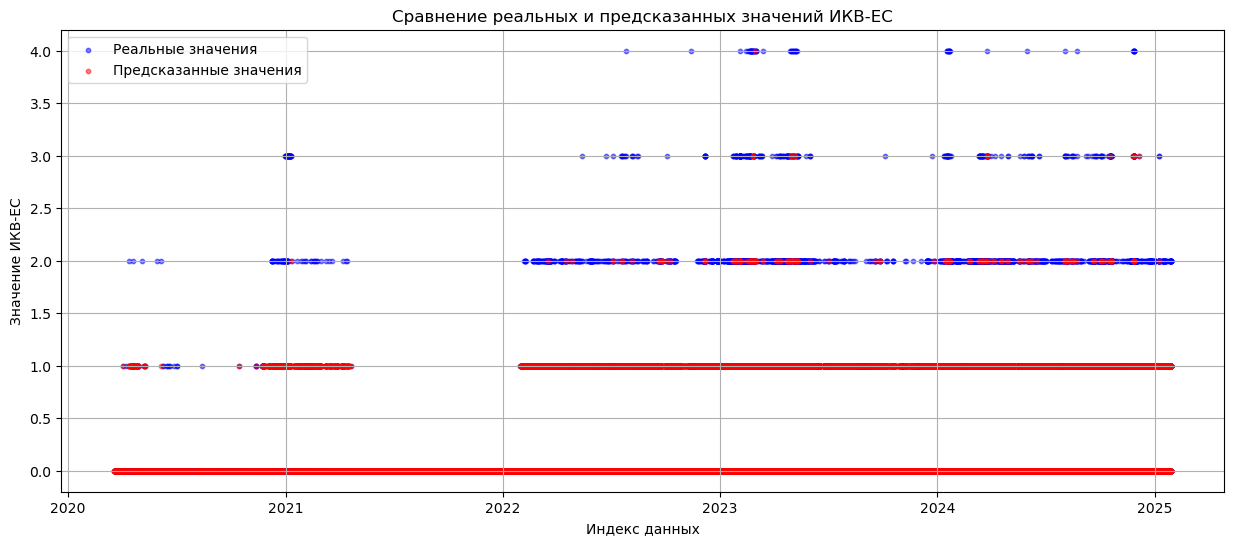

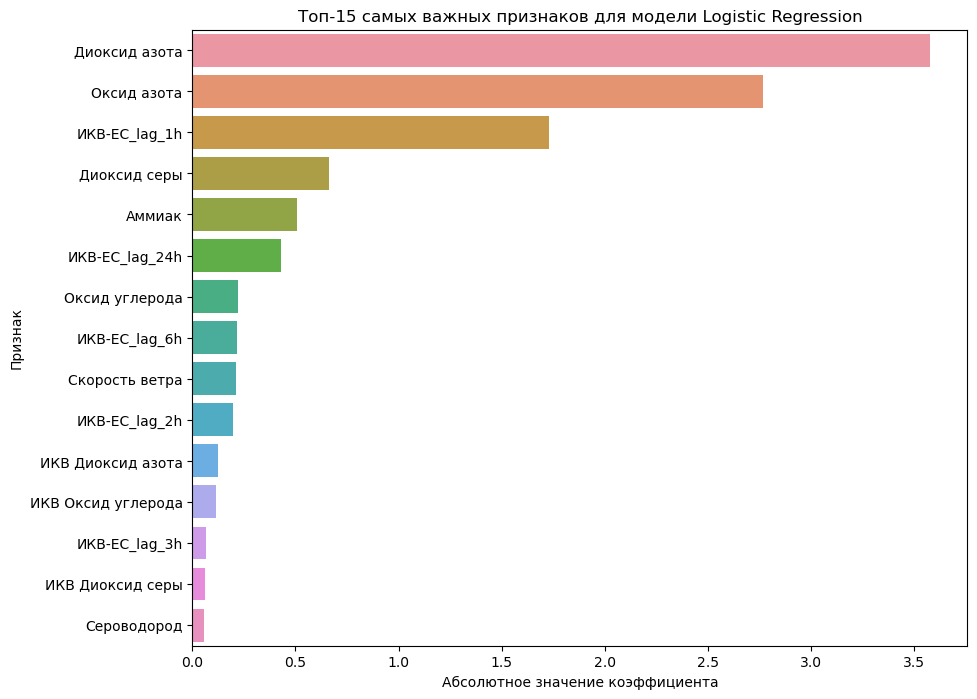

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression # Изменено: теперь импортируем LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Определяем целевую переменную
TARGET = 'ИКВ-ЕС'

# Отделяем признаки (X) от целевой переменной (y)
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

# Разделяем данные на обучающую и тестовую выборки (80% на обучение, 20% на тест)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Инициализация LogisticRegression ---
# Logistic Regression не имеет параметров n_estimators, max_features, min_samples_leaf.
# Вместо этого используются свои параметры, такие как C (обратная сила регуляризации) и solver.
log_reg_classifier = LogisticRegression(
    C=1.0,               # Обратная сила регуляризации; меньшие значения означают более сильную регуляризацию
    solver='liblinear',  # Алгоритм, используемый в задаче оптимизации. 'liblinear' хорошо подходит для небольших наборов данных.
    random_state=42,     # Для воспроизводимости
    n_jobs=-1            # Использовать все доступные ядра процессора для ускорения
)

print(f"\n--- Обучение модели LogisticRegression ---")
log_reg_classifier.fit(X_train, y_train)

# --- Оценка и демонстрация ---
# Прогнозирование на тестовой выборке
y_pred = log_reg_classifier.predict(X_test)

# --- Расчёт метрик качества для классификации ---
print(f"\n--- Качество модели на тестовых данных ---")

# Точность (Accuracy): Доля правильно классифицированных образцов
accuracy = accuracy_score(y_test, y_pred)
print(f"Точность (Accuracy): {accuracy:.4f}")

# Матрица ошибок (Confusion Matrix): Визуализация производительности классификатора
# Показывает количество правильных и неправильных предсказаний для каждого класса
print("\nМатрица ошибок (Confusion Matrix):")
labels = sorted(y.unique()) # Получаем все уникальные классы из целевой переменной
conf_matrix = confusion_matrix(y_test, y_pred, labels=labels)
print(conf_matrix)

# Отчёт по классификации (Classification Report):
# Включает Precision, Recall, F1-score и Support для каждого класса
print("\nОтчёт по классификации (Classification Report):")
print(classification_report(y_test, y_pred, target_names=[str(c) for c in labels]))

# --- График сравнения реальных и предсказанных значений ---
plt.figure(figsize=(15, 6))
plt.scatter(y_test.index, y_test, label='Реальные значения', color='blue', alpha=0.5, s=10)
plt.scatter(y_test.index, y_pred, label='Предсказанные значения', color='red', alpha=0.5, s=10)
plt.title(f'Сравнение реальных и предсказанных значений {TARGET}')
plt.xlabel('Индекс данных') # Или 'Время', если у вас есть временной индекс
plt.ylabel(f'Значение {TARGET}') # Или соответствующая единица измерения
plt.legend()
plt.grid(True)
plt.show()

# --- График важности признаков ---
# Logistic Regression имеет коэффициенты (coef_), которые показывают важность признаков.
# Для бинарной классификации coef_ будет одномерным массивом, для мультиклассовой - двумерным.
if hasattr(log_reg_classifier, 'coef_'):
    # Если это мультиклассовая классификация (больше 2 классов),
    # можно взять абсолютное среднее значение коэффициентов по классам
    if log_reg_classifier.coef_.ndim > 1:
        feature_importances = pd.Series(np.abs(log_reg_classifier.coef_).mean(axis=0), index=X.columns).sort_values(ascending=False)
    else: # Бинарная классификация
        feature_importances = pd.Series(np.abs(log_reg_classifier.coef_[0]), index=X.columns).sort_values(ascending=False)

    plt.figure(figsize=(10, 8))
    sns.barplot(x=feature_importances.head(15), y=feature_importances.head(15).index)
    plt.title('Топ-15 самых важных признаков для модели Logistic Regression')
    plt.xlabel('Абсолютное значение коэффициента')
    plt.ylabel('Признак')
    plt.show()
else:
    print("\nМодель не имеет атрибута 'coef_'.")

Ошибка скорее всего из-за того, что класс "Очень высокий" уровень ИКВ (5) встречается очень редко, модели сложно дообучиться

### 3. KNeighborsClassifier


--- Обучение модели KNeighborsClassifier ---


C:\ProgramData\Anaconda3\lib\site-packages\sklearn\neighbors\_classification.py:228: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)



--- Качество модели на тестовых данных ---
Точность (Accuracy): 0.9428

Матрица ошибок (Confusion Matrix):
[[45014   940    20     1     7]
 [ 1423  8815   247     0     1]
 [   19   554  1771    43     0]
 [    2     0    97   231    10]
 [    6     2     2    14    37]]

Отчёт по классификации (Classification Report):
              precision    recall  f1-score   support

         0.0       0.97      0.98      0.97     45982
         1.0       0.85      0.84      0.85     10486
         2.0       0.83      0.74      0.78      2387
         3.0       0.80      0.68      0.73       340
         4.0       0.67      0.61      0.64        61

    accuracy                           0.94     59256
   macro avg       0.82      0.77      0.80     59256
weighted avg       0.94      0.94      0.94     59256



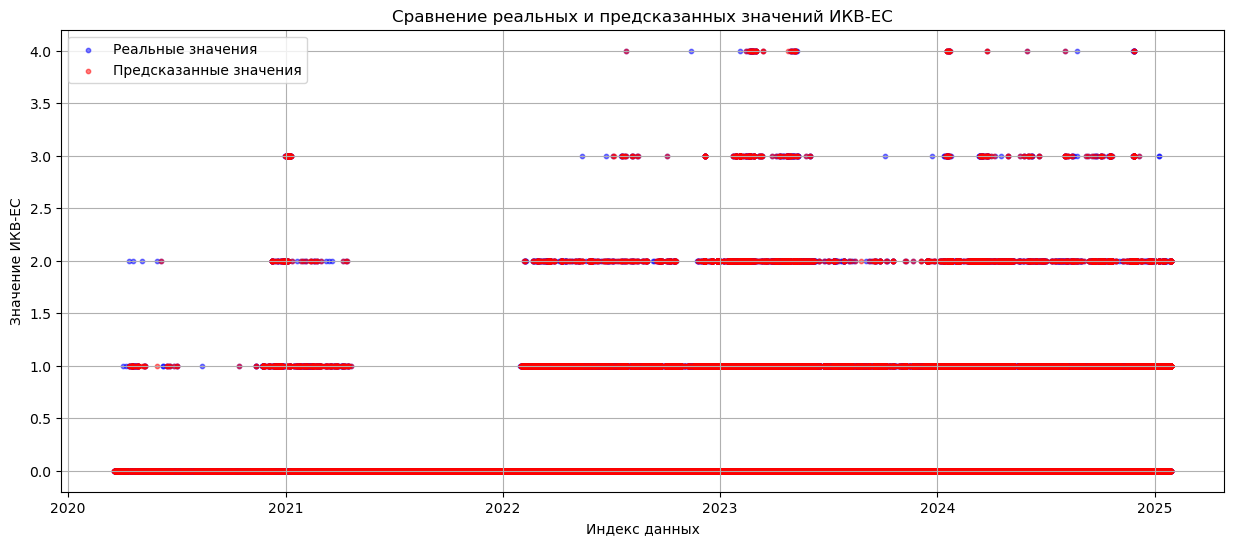

C:\ProgramData\Anaconda3\lib\site-packages\sklearn\neighbors\_classification.py:228: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler # Для масштабирования признаков
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Отделяем признаки (X) от целевой переменной (y)
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

# Разделяем данные на обучающую и тестовую выборки (80% на обучение, 20% на тест)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Масштабирование признаков ---
# KNeighborsClassifier основан на расстоянии, поэтому масштабирование признаков критически важно.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Преобразуем обратно в DataFrame для сохранения названий столбцов
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

# --- Инициализация KNeighborsClassifier ---
# Основной параметр для KNN - n_neighbors (количество ближайших соседей).
knn_classifier = KNeighborsClassifier(
    n_neighbors=5,       # Количество соседей для голосования
    weights='uniform',   # 'uniform' (все соседи имеют одинаковый вес) или 'distance' (вес пропорционален обратной величине расстояния)
    metric='euclidean',  # Метрика расстояния (например, 'euclidean', 'manhattan', 'minkowski')
    n_jobs=-1            # Использовать все доступные ядра процессора для ускорения
)

print(f"\n--- Обучение модели KNeighborsClassifier ---")
# Обучаем модель на масштабированных данных
knn_classifier.fit(X_train_scaled, y_train)

# --- Оценка и демонстрация ---
# Прогнозирование на масштабированной тестовой выборке
y_pred = knn_classifier.predict(X_test_scaled)

# --- Расчёт метрик качества для классификации ---
print(f"\n--- Качество модели на тестовых данных ---")

# Точность (Accuracy): Доля правильно классифицированных образцов
accuracy = accuracy_score(y_test, y_pred)
print(f"Точность (Accuracy): {accuracy:.4f}")

# Матрица ошибок (Confusion Matrix): Визуализация производительности классификатора
print("\nМатрица ошибок (Confusion Matrix):")
labels = sorted(y.unique())
conf_matrix = confusion_matrix(y_test, y_pred, labels=labels)
print(conf_matrix)

# Отчёт по классификации (Classification Report):
print("\nОтчёт по классификации (Classification Report):")
print(classification_report(y_test, y_pred, target_names=[str(c) for c in labels]))

# --- График сравнения реальных и предсказанных значений ---
plt.figure(figsize=(15, 6))
plt.scatter(y_test.index, y_test, label='Реальные значения', color='blue', alpha=0.5, s=10)
plt.scatter(y_test.index, y_pred, label='Предсказанные значения', color='red', alpha=0.5, s=10)
plt.title(f'Сравнение реальных и предсказанных значений {TARGET}')
plt.xlabel('Индекс данных')
plt.ylabel(f'Значение {TARGET}')
plt.legend()
plt.grid(True)
plt.show()

# --- График важности признаков ---
# KNeighborsClassifier не имеет атрибута feature_importances_ или coef_.
# Он не является моделью, основанной на деревьях или линейных коэффициентах.
# Важность признаков для KNN определяется их влиянием на расстояние.
# Для анализа важности признаков в KNN обычно используют другие методы,
# например, Permutation Importance.

from sklearn.inspection import permutation_importance

r = permutation_importance(knn_classifier, X_test_scaled, y_test,
                           n_repeats=30,
                           random_state=42,
                           n_jobs=-1)

sorted_idx = r.importances_mean.argsort()
plt.figure(figsize=(10, 8))
sns.barplot(x=r.importances_mean[sorted_idx][-15:], y=X_test_scaled.columns[sorted_idx][-15:])
plt.title("Топ-15 самых важных признаков (Permutation Importance)")
plt.xlabel("Важность признака")
plt.ylabel("Признак")
plt.show()

### 4. XGBoost

In [7]:
# pip install xgboost


--- Обучение модели XGBClassifier ---


C:\ProgramData\Anaconda3\lib\site-packages\xgboost\core.py:158: UserWarning: [23:04:48] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



--- Качество модели на тестовых данных ---
Точность (Accuracy): 0.9891

Матрица ошибок (Confusion Matrix):
[[45847   126     4     0     5]
 [   99 10245   141     0     1]
 [    5   129  2194    59     0]
 [    1     3    35   288    13]
 [    4     2     1    17    37]]

Отчёт по классификации (Classification Report):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     45982
           1       0.98      0.98      0.98     10486
           2       0.92      0.92      0.92      2387
           3       0.79      0.85      0.82       340
           4       0.66      0.61      0.63        61

    accuracy                           0.99     59256
   macro avg       0.87      0.87      0.87     59256
weighted avg       0.99      0.99      0.99     59256



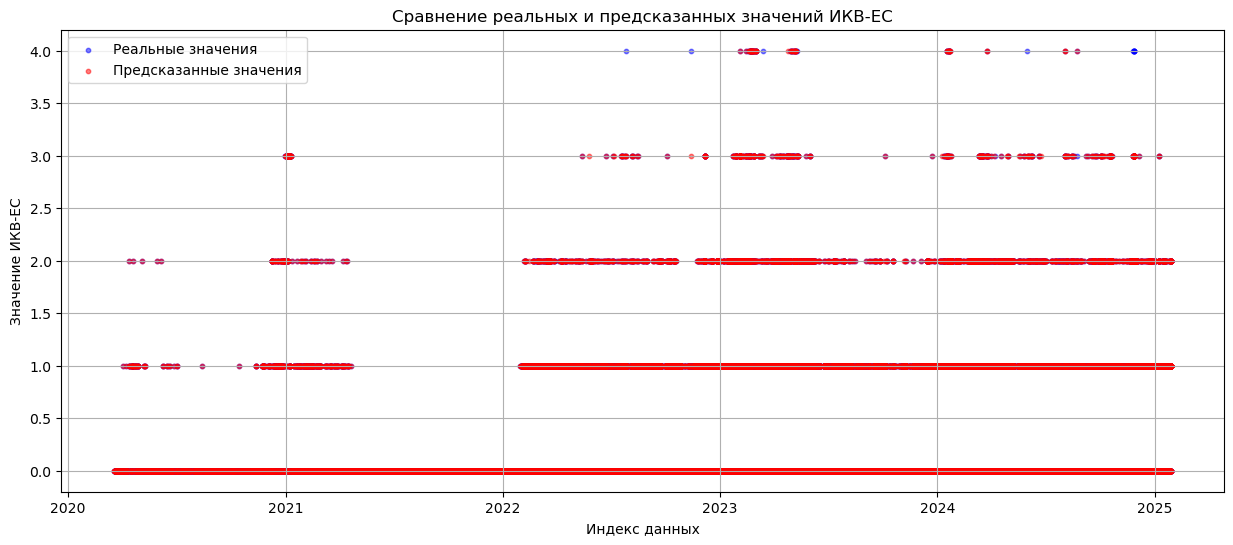

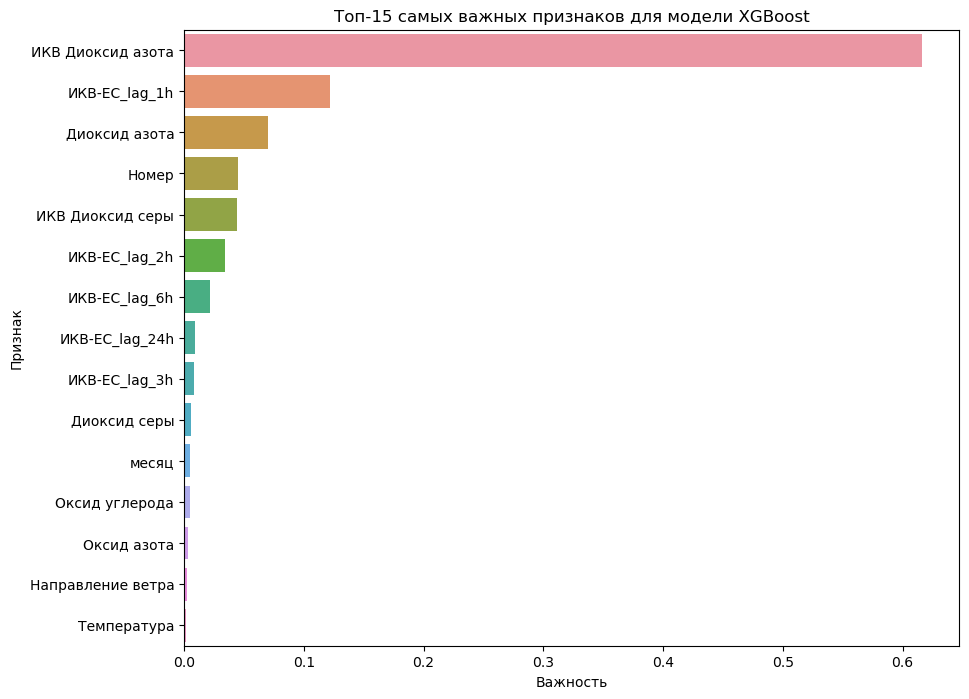

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
import xgboost as xgb

# Отделяем признаки (X) от целевой переменной (y)
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

if y.min() == 1 and y.max() == 5: # Сюда обязательно требуется нумерация от 0
    y = y - 1
y = y.astype(int)

# Разделяем данные на обучающую и тестовую выборки (80% на обучение, 20% на тест)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Инициализация XGBClassifier ---
xgb_classifier = xgb.XGBClassifier(
    objective='multi:softmax', # Для мультиклассовой классификации (т.к. 2+ класса)
    n_estimators=100,          # Количество бустинговых деревьев
    learning_rate=0.1,         # Скорость обучения
    max_depth=3,               # Максимальная глубина дерева
    use_label_encoder=False,   # Отключает устаревший LabelEncoder (важно для последних версий XGBoost)
    eval_metric='mlogloss',    # Метрика оценки для мультиклассовой классификации.
                               # Для бинарной классификации: 'logloss' или 'error'
    random_state=42,           # Для воспроизводимости
    n_jobs=-1                  # Использовать все доступные ядра процессора для ускорения
)

print(f"\n--- Обучение модели XGBClassifier ---")
xgb_classifier.fit(X_train, y_train)

# --- Оценка и демонстрация ---
# Прогнозирование на тестовой выборке
y_pred = xgb_classifier.predict(X_test)

# --- Расчёт метрик качества для классификации ---
print(f"\n--- Качество модели на тестовых данных ---")

# Точность (Accuracy): Доля правильно классифицированных образцов
accuracy = accuracy_score(y_test, y_pred)
print(f"Точность (Accuracy): {accuracy:.4f}")

# Матрица ошибок (Confusion Matrix): Визуализация производительности классификатора
# Показывает количество правильных и неправильных предсказаний для каждого класса
print("\nМатрица ошибок (Confusion Matrix):")
labels = sorted(y.unique()) # Получаем все уникальные классы из целевой переменной
conf_matrix = confusion_matrix(y_test, y_pred, labels=labels)
print(conf_matrix)

# Отчёт по классификации (Classification Report):
# Включает Precision, Recall, F1-score и Support для каждого класса
print("\nОтчёт по классификации (Classification Report):")
print(classification_report(y_test, y_pred, target_names=[str(c) for c in labels]))

# --- График сравнения реальных и предсказанных значений ---
plt.figure(figsize=(15, 6))
plt.scatter(y_test.index, y_test, label='Реальные значения', color='blue', alpha=0.5, s=10)
plt.scatter(y_test.index, y_pred, label='Предсказанные значения', color='red', alpha=0.5, s=10)
plt.title(f'Сравнение реальных и предсказанных значений {TARGET}')
plt.xlabel('Индекс данных') # Или 'Время', если у вас есть временной индекс
plt.ylabel(f'Значение {TARGET}') # Или соответствующая единица измерения
plt.legend()
plt.grid(True)
plt.show()

# --- График важности признаков ---
if hasattr(xgb_classifier, 'feature_importances_'):
    feature_importances = pd.Series(xgb_classifier.feature_importances_, index=X.columns).sort_values(ascending=False)
    plt.figure(figsize=(10, 8))
    sns.barplot(x=feature_importances.head(15), y=feature_importances.head(15).index)
    plt.title('Топ-15 самых важных признаков для модели XGBoost')
    plt.xlabel('Важность')
    plt.ylabel('Признак')
    plt.show()
else:
    print("\nМодель не имеет атрибута 'feature_importances_'.")

### 5. LightGBM

In [9]:
# pip install lightgbm


--- Обучение модели LGBMClassifier ---
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012732 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2418
[LightGBM] [Info] Number of data points in the train set: 237021, number of used features: 22
[LightGBM] [Info] Start training from score -0.252892
[LightGBM] [Info] Start training from score -1.747286
[LightGBM] [Info] Start training from score -3.152845
[LightGBM] [Info] Start training from score -5.233867
[LightGBM] [Info] Start training from score -6.777482

--- Качество модели на тестовых данных ---
Точность (Accuracy): 0.9494

Матрица ошибок (Confusion Matrix):
[[45489   320    78    56    39]
 [ 1128  8586   475   213    84]
 [  113   194  2020    47    13]
 [   18     7   167   138    10]
 [    5     7   

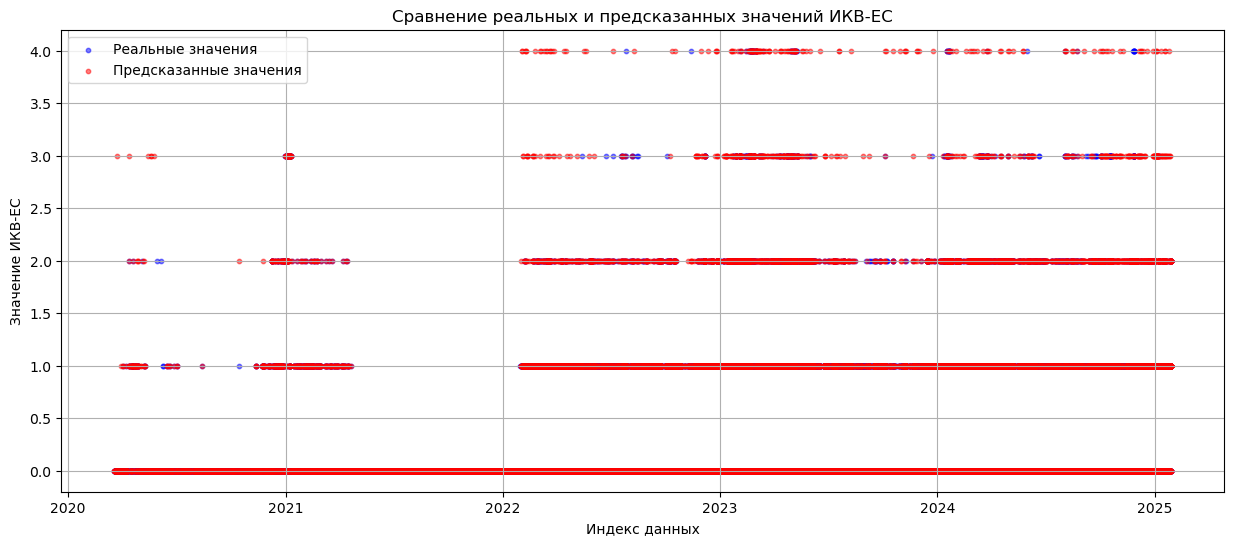

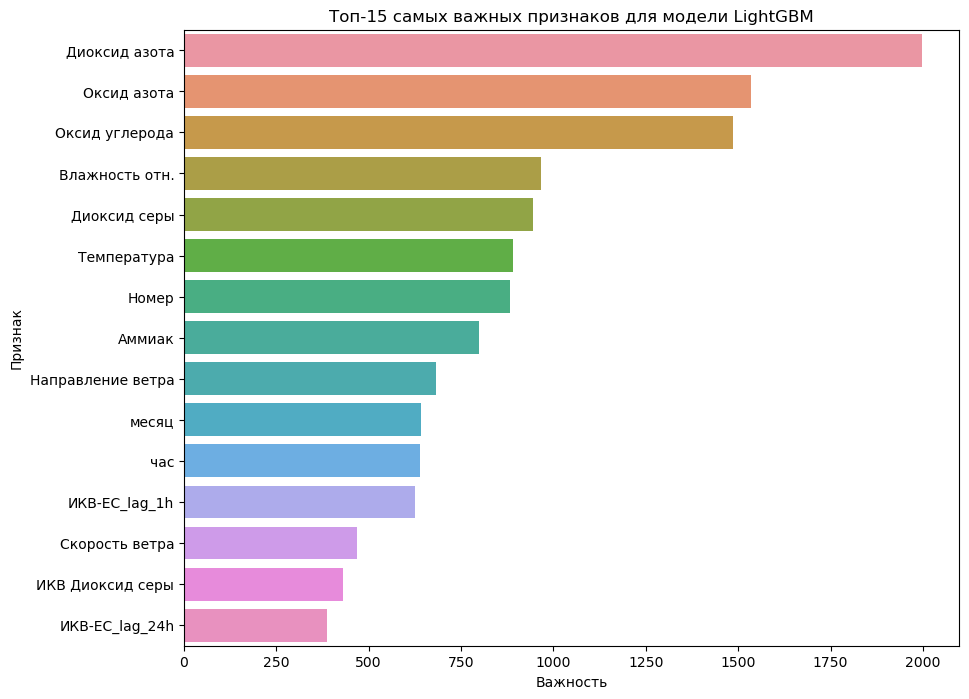

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
import lightgbm as lgb

# Отделяем признаки (X) от целевой переменной (y)
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

if y.min() == 1 and y.max() == 5: # Сюда обязательно требуется нумерация от 0
    y = y - 1
y = y.astype(int)

# Разделяем данные на обучающую и тестовую выборки (80% на обучение, 20% на тест)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Инициализация LGBMClassifier ---
lgbm_classifier = lgb.LGBMClassifier(
    objective='multiclass',    # Для мультиклассовой классификации (т.к. 2+ класса)
    num_class=len(y.unique()), # Необходимо указать количество классов для мультиклассовой задачи
    n_estimators=100,          # Количество бустинговых деревьев
    learning_rate=0.1,         # Скорость обучения
    num_leaves=31,             # Максимальное количество листьев в дереве (по умолчанию 31)
    random_state=42,           # Для воспроизводимости
    n_jobs=-1                  # Использовать все доступные ядра процессора для ускорения
)

print(f"\n--- Обучение модели LGBMClassifier ---")
lgbm_classifier.fit(X_train, y_train)

# --- Оценка и демонстрация ---
# Прогнозирование на тестовой выборке
y_pred = lgbm_classifier.predict(X_test)

# --- Расчёт метрик качества для классификации ---
print(f"\n--- Качество модели на тестовых данных ---")

# Точность (Accuracy): Доля правильно классифицированных образцов
accuracy = accuracy_score(y_test, y_pred)
print(f"Точность (Accuracy): {accuracy:.4f}")

# Матрица ошибок (Confusion Matrix): Визуализация производительности классификатора
# Показывает количество правильных и неправильных предсказаний для каждого класса
print("\nМатрица ошибок (Confusion Matrix):")
labels = sorted(y.unique()) # Получаем все уникальные классы из целевой переменной
conf_matrix = confusion_matrix(y_test, y_pred, labels=labels)
print(conf_matrix)

# Отчёт по классификации (Classification Report):
# Включает Precision, Recall, F1-score и Support для каждого класса
print("\nОтчёт по классификации (Classification Report):")
print(classification_report(y_test, y_pred, target_names=[str(c) for c in labels]))

# --- График сравнения реальных и предсказанных значений ---
plt.figure(figsize=(15, 6))
plt.scatter(y_test.index, y_test, label='Реальные значения', color='blue', alpha=0.5, s=10)
plt.scatter(y_test.index, y_pred, label='Предсказанные значения', color='red', alpha=0.5, s=10)
plt.title(f'Сравнение реальных и предсказанных значений {TARGET}')
plt.xlabel('Индекс данных') # Или 'Время', если у вас есть временной индекс
plt.ylabel(f'Значение {TARGET}') # Или соответствующая единица измерения
plt.legend()
plt.grid(True)
plt.show()

# --- График важности признаков ---
if hasattr(lgbm_classifier, 'feature_importances_'):
    feature_importances = pd.Series(lgbm_classifier.feature_importances_[:len(X.columns)], index=X.columns).sort_values(ascending=False) # важность по gain
    
    plt.figure(figsize=(10, 8))
    sns.barplot(x=feature_importances.head(15), y=feature_importances.head(15).index)
    plt.title('Топ-15 самых важных признаков для модели LightGBM')
    plt.xlabel('Важность')
    plt.ylabel('Признак')
    plt.show()
else:
    print("\nМодель не имеет атрибута 'feature_importances_'.")

### 6. CatBoost

In [11]:
#pip install catboost


--- Обучение модели CatBoostClassifier ---

--- Качество модели на тестовых данных ---
Точность (Accuracy): 0.9912

Матрица ошибок (Confusion Matrix):
[[45842   130     4     0     6]
 [  103 10335    46     0     2]
 [    6   133  2213    35     0]
 [    1     4    28   297    10]
 [    4     2     0     5    50]]

Отчёт по классификации (Classification Report):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     45982
           1       0.97      0.99      0.98     10486
           2       0.97      0.93      0.95      2387
           3       0.88      0.87      0.88       340
           4       0.74      0.82      0.78        61

    accuracy                           0.99     59256
   macro avg       0.91      0.92      0.92     59256
weighted avg       0.99      0.99      0.99     59256



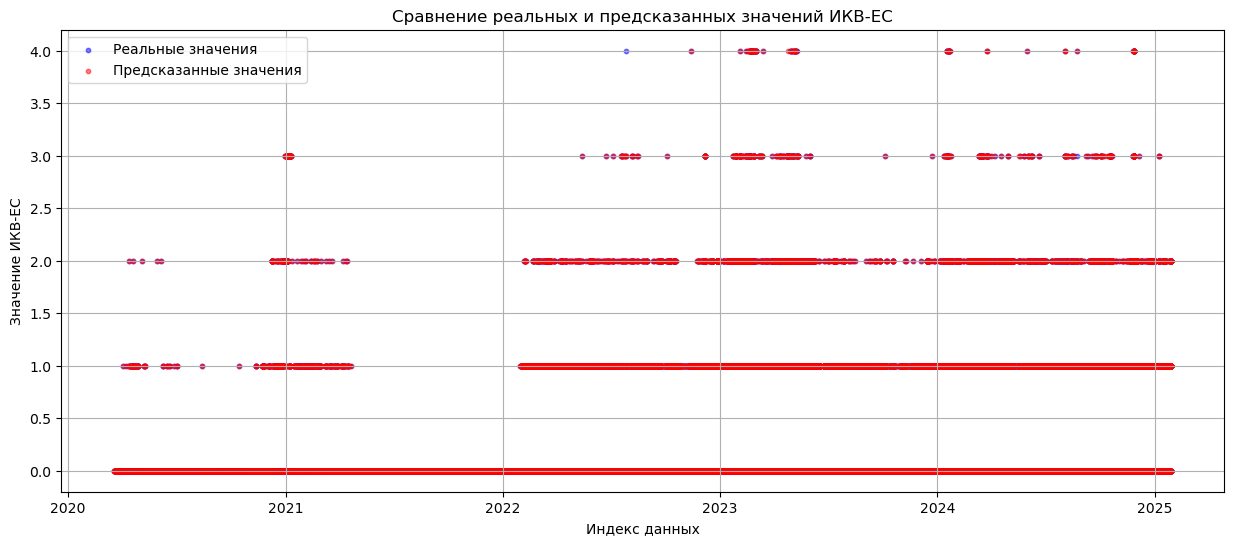

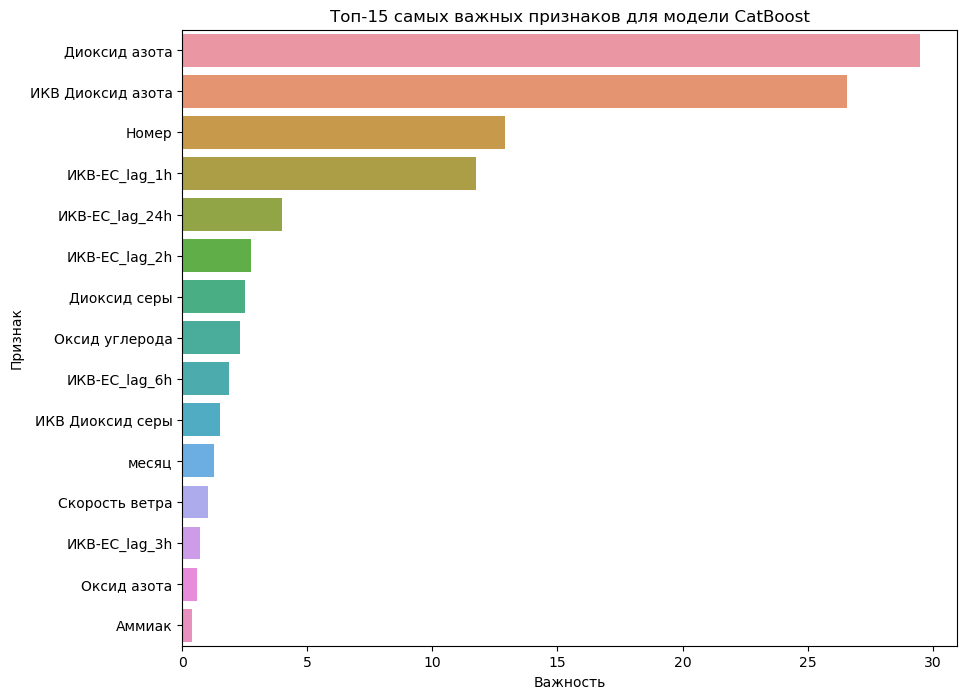

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
from catboost import CatBoostClassifier, Pool

# Отделяем признаки (X) от целевой переменной (y)
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

if y.min() == 1 and y.max() == 5: # Сюда обязательно требуется нумерация от 0
    y = y - 1
y = y.astype(int)

# Разделяем данные на обучающую и тестовую выборки (80% на обучение, 20% на тест)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Определение категориальных признаков ---
# CatBoost может автоматически обрабатывать категориальные признаки.
# Важно указать, какие столбцы являются категориальными.
# Если у вас нет категориальных признаков, этот список будет пустым.
categorical_features_indices = [i for i, col in enumerate(X.columns) if X[col].dtype == 'object' or X[col].dtype == 'category']
# Если у вас есть категориальные признаки, но они в числовом формате (например, 0, 1, 2, но на самом деле категории),
# вам нужно будет явно указать их индексы или названия.
# Например: categorical_features_indices = [X.columns.get_loc('НазваниеКатегориальногоПризнака')]

# --- Инициализация CatBoostClassifier ---
cat_classifier = CatBoostClassifier(
    iterations=100,            # Количество бустинговых деревьев
    learning_rate=0.1,         # Скорость обучения
    depth=6,                   # Максимальная глубина дерева
    loss_function='MultiClass',# Для мультиклассовой классификации (т.к. 2+ класса)
    eval_metric='Accuracy',    # Метрика для оценки во время обучения
    random_seed=42,            # Для воспроизводимости
    verbose=0,                 # Установите в 10 или больше, чтобы видеть прогресс обучения
    cat_features=categorical_features_indices, # Передаем индексы категориальных признаков
)

print(f"\n--- Обучение модели CatBoostClassifier ---")
cat_classifier.fit(X_train, y_train)

# --- Оценка и демонстрация ---
# Прогнозирование на тестовой выборке
y_pred = cat_classifier.predict(X_test)
# CatBoost.predict возвращает одномерный массив для MultiClass,
# но он может вернуть двумерный массив (вероятности) для Logloss,
# поэтому иногда может потребоваться flatten, если классов много
y_pred = y_pred.flatten()


# --- Расчёт метрик качества для классификации ---
print(f"\n--- Качество модели на тестовых данных ---")

# Точность (Accuracy): Доля правильно классифицированных образцов
accuracy = accuracy_score(y_test, y_pred)
print(f"Точность (Accuracy): {accuracy:.4f}")

# Матрица ошибок (Confusion Matrix): Визуализация производительности классификатора
# Показывает количество правильных и неправильных предсказаний для каждого класса
print("\nМатрица ошибок (Confusion Matrix):")
labels = sorted(y.unique()) # Получаем все уникальные классы из целевой переменной
conf_matrix = confusion_matrix(y_test, y_pred, labels=labels)
print(conf_matrix)

# Отчёт по классификации (Classification Report):
# Включает Precision, Recall, F1-score и Support для каждого класса
print("\nОтчёт по классификации (Classification Report):")
print(classification_report(y_test, y_pred, target_names=[str(c) for c in labels]))

# --- График сравнения реальных и предсказанных значений ---
plt.figure(figsize=(15, 6))
plt.scatter(y_test.index, y_test, label='Реальные значения', color='blue', alpha=0.5, s=10)
plt.scatter(y_test.index, y_pred, label='Предсказанные значения', color='red', alpha=0.5, s=10)
plt.title(f'Сравнение реальных и предсказанных значений {TARGET}')
plt.xlabel('Индекс данных') # Или 'Время', если у вас есть временной индекс
plt.ylabel(f'Значение {TARGET}') # Или соответствующая единица измерения
plt.legend()
plt.grid(True)
plt.show()

# --- График важности признаков ---
if hasattr(cat_classifier, 'get_feature_importance'):
    feature_importances = cat_classifier.get_feature_importance(Pool(X_train, y_train, cat_features=categorical_features_indices))
    feature_importances_series = pd.Series(feature_importances, index=X.columns).sort_values(ascending=False)

    plt.figure(figsize=(10, 8))
    sns.barplot(x=feature_importances_series.head(15), y=feature_importances_series.head(15).index)
    plt.title('Топ-15 самых важных признаков для модели CatBoost')
    plt.xlabel('Важность')
    plt.ylabel('Признак')
    plt.show()
else:
    print("\nМодель не имеет атрибута 'get_feature_importance'.")